# Classification and Model Improvement: Breast Cancer Diagnosis
**Purpose:** Build and evaluate a basic classification model that predicts whether a breast tumour is malignant or benign.

**Dataset:** Wisconsin Diagnostic Breast Cancer dataset supplied with `scikit-learn`. The dataset contains numeric measurements computed from digitised images of breast mass samples. The target labels are *malignant* and *benign*.

> Run the notebook from top to bottom. Metrics and charts are generated by the code, so the reported results come from the actual run rather than assumed scores.

## 1. Import libraries
We use pandas and NumPy for data handling, Matplotlib/Seaborn for visualisation, and scikit-learn for the dataset, preprocessing, models and evaluation.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, ConfusionMatrixDisplay,
    roc_auc_score
)

RANDOM_STATE = 42
sns.set_theme()

## 2. Load and explore the dataset
Each row represents a sample. The predictors are numeric tumour measurements such as radius, texture, perimeter and area. The target is diagnosis. In scikit-learn, target value `0` means malignant and `1` means benign; we create readable labels for plots.

In [2]:
data = load_breast_cancer(as_frame=True)
df = data.frame.copy()
df = df.rename(columns={"target": "target_code"})
df["diagnosis"] = df["target_code"].map({0: "malignant", 1: "benign"})

print("Dataset shape:", df.shape)
display(df.head())
print("\\nData types:")
print(df.dtypes.value_counts())
print("\\nMissing values (largest counts first):")
print(df.isna().sum().sort_values(ascending=False).head(10))
print("\\nSummary statistics:")
display(df.describe().T.head(10))
print("\\nDiagnosis counts:")
print(df["diagnosis"].value_counts())

Dataset shape: (569, 32)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target_code,diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0,malignant
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0,malignant
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0,malignant
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0,malignant
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0,malignant


\nData types:
float64    30
int64       1
str         1
Name: count, dtype: int64
\nMissing values (largest counts first):
mean radius               0
mean texture              0
mean perimeter            0
mean area                 0
mean smoothness           0
mean compactness          0
mean concavity            0
mean concave points       0
mean symmetry             0
mean fractal dimension    0
dtype: int64
\nSummary statistics:


,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.98100,11.70000,13.37000,15.78000,28.11000
mean texture,569.0,19.289649,4.301036,9.71000,16.17000,18.84000,21.80000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.79000,75.17000,86.24000,104.10000,188.50000
mean area,569.0,654.889104,351.914129,143.50000,420.30000,551.10000,782.70000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.05263,0.08637,0.09587,0.10530,0.16340
mean compactness,569.0,0.104341,0.052813,0.01938,0.06492,0.09263,0.13040,0.34540
mean concavity,569.0,0.088799,0.079720,0.00000,0.02956,0.06154,0.13070,0.42680
mean concave points,569.0,0.048919,0.038803,0.00000,0.02031,0.03350,0.07400,0.20120
mean symmetry,569.0,0.181162,0.027414,0.10600,0.16190,0.17920,0.19570,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.04996,0.05770,0.06154,0.06612,0.09744


\nDiagnosis counts:
diagnosis
benign       357
malignant    212
Name: count, dtype: int64


## 3. Exploratory Data Analysis (EDA)
We check class balance, examine a selection of feature distributions, and view relationships between key features and diagnosis. Visual patterns can guide modelling, but they do not establish medical causation.

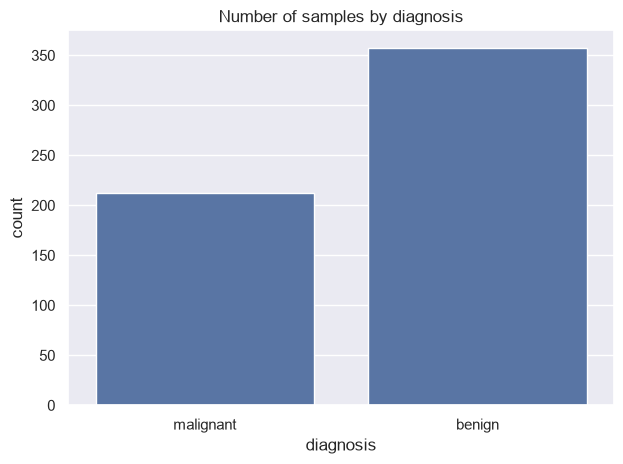

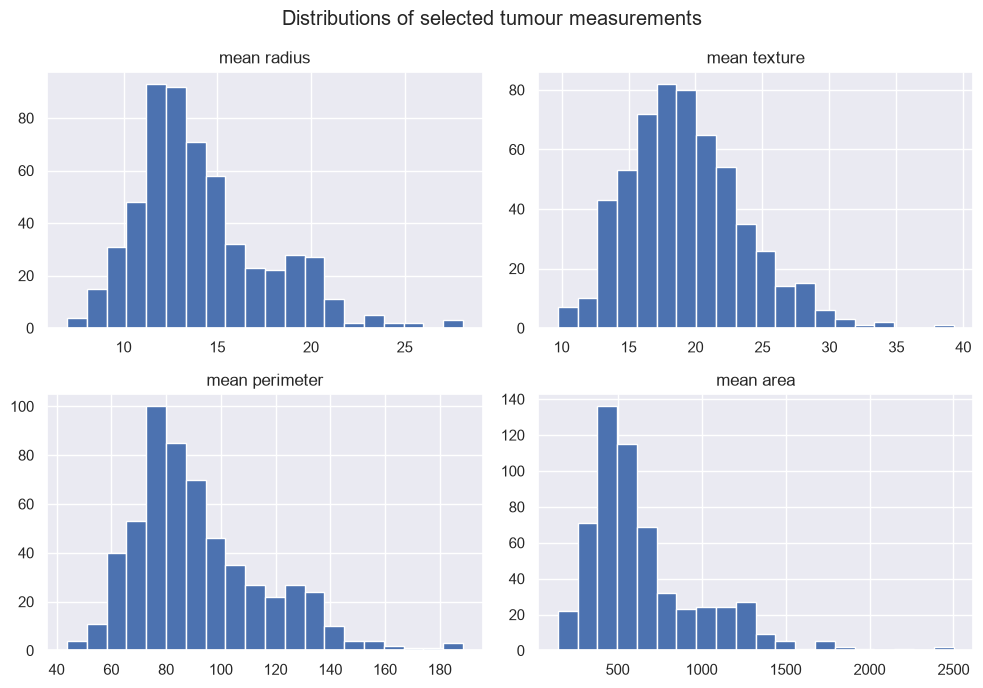

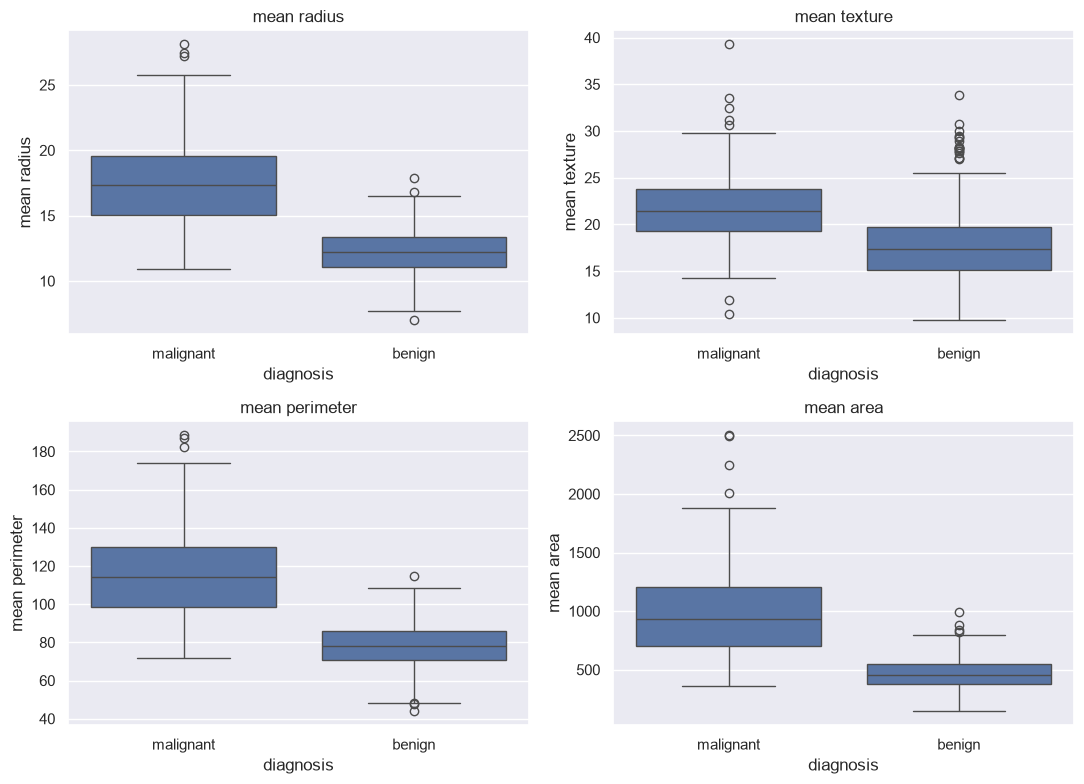

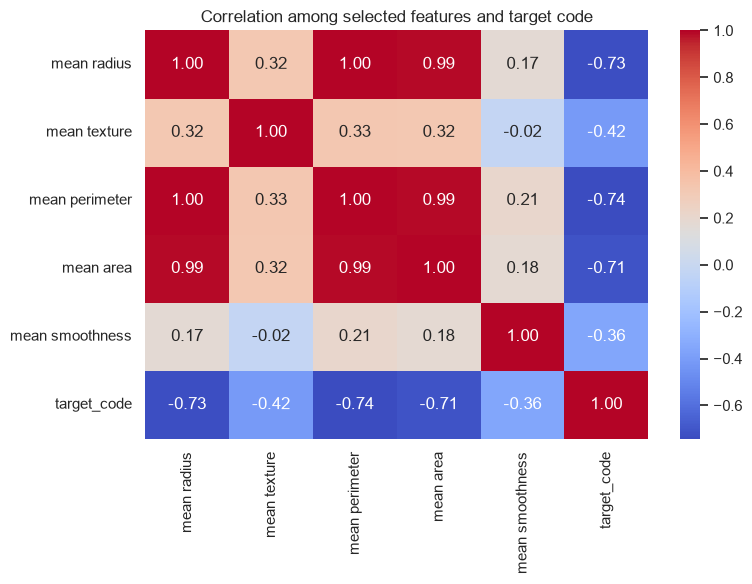

In [3]:
# Class balance
ax = sns.countplot(data=df, x="diagnosis")
ax.set_title("Number of samples by diagnosis")
plt.tight_layout()
plt.show()

# Distribution of selected measurements
features_to_plot = ["mean radius", "mean texture", "mean perimeter", "mean area"]
df[features_to_plot].hist(figsize=(10, 7), bins=20)
plt.suptitle("Distributions of selected tumour measurements")
plt.tight_layout()
plt.show()

# Compare selected measurements by diagnosis
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for feature, ax in zip(features_to_plot, axes.ravel()):
    sns.boxplot(data=df, x="diagnosis", y=feature, ax=ax)
    ax.set_title(feature)
plt.tight_layout()
plt.show()

# Correlation heatmap for a small set of features
corr_features = ["mean radius", "mean texture", "mean perimeter", "mean area",
                 "mean smoothness", "target_code"]
plt.figure(figsize=(8, 6))
sns.heatmap(df[corr_features].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation among selected features and target code")
plt.tight_layout()
plt.show()

### EDA interpretation
The class-count plot shows the number of malignant and benign samples in this dataset. Boxplots help compare the distributions of selected tumour measurements between the two classes. Several size-related measurements may show visible differences between classes. Correlations can also reveal that some size variables overlap strongly with each other, which is a reason to use scaling and regularisation for logistic regression. These patterns should be described from the generated charts; they are not proof that any feature causes cancer.

## 4. Data cleaning and preprocessing
The dataset is already structured and numeric. We check for missing values and duplicates. We keep the diagnosis label separate from predictors, then split the data before fitting any transformation to avoid data leakage.

In [4]:
# Check data quality
print("Missing cells:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))

# The source dataset is expected to have no missing values.
# Drop duplicate records if any are present.
df = df.drop_duplicates().copy()

X = df.drop(columns=["target_code", "diagnosis"])
y = df["target_code"]  # 0 = malignant, 1 = benign

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])

Missing cells: 0
Duplicate rows: 0
Training rows: 455
Testing rows: 114


## 5. Feature selection and model choice
We use the measured numeric features as predictors for a baseline model. Logistic Regression is a suitable baseline because it is a widely used classification method, can produce class probabilities, and is relatively interpretable. Standardisation is included in a pipeline because feature scales differ. A Random Forest is also trained as a comparison model because it can capture non-linear relationships.

In [5]:
logistic_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=5000, class_weight="balanced",
                                 random_state=RANDOM_STATE))
])
logistic_pipeline.fit(X_train, y_train)

rf_model = RandomForestClassifier(
    n_estimators=300, random_state=RANDOM_STATE,
    class_weight="balanced"
)
rf_model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.

## 6. Evaluation
We report accuracy, precision, recall and F1-score. Because missing a malignant case can have serious consequences, recall for the malignant class is especially important. In this dataset, label `0` is malignant, so the malignant-class metrics are calculated with `pos_label=0`. These models are educational examples, not tools for clinical diagnosis.

,Model,Accuracy,Malignant precision,Malignant recall,Malignant F1
0,Logistic Regression (baseline),0.956,0.911,0.976,0.943
1,Random Forest (comparison),0.939,0.907,0.929,0.918


Model with highest malignant recall on this split: Logistic Regression (baseline)
\n Logistic Regression
              precision    recall  f1-score   support

   malignant       0.91      0.98      0.94        42
      benign       0.99      0.94      0.96        72

    accuracy                           0.96       114
   macro avg       0.95      0.96      0.95       114
weighted avg       0.96      0.96      0.96       114



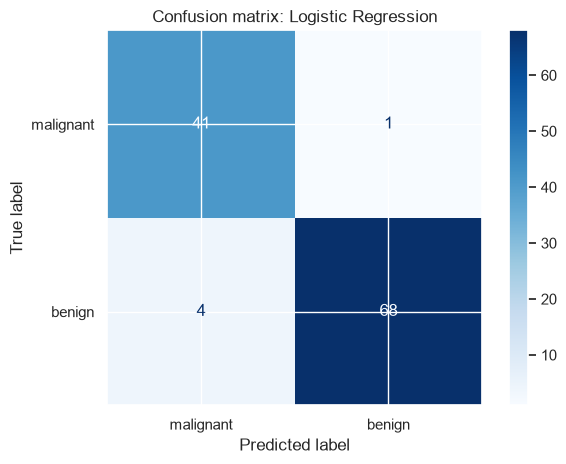

\n Random Forest
              precision    recall  f1-score   support

   malignant       0.91      0.93      0.92        42
      benign       0.96      0.94      0.95        72

    accuracy                           0.94       114
   macro avg       0.93      0.94      0.93       114
weighted avg       0.94      0.94      0.94       114



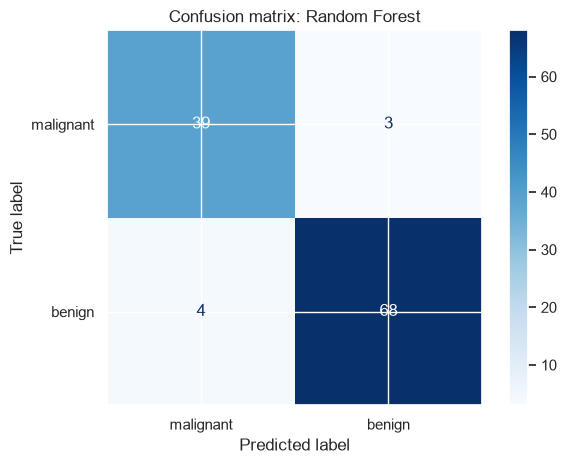

In [6]:
def evaluate_model(name, model, X_test, y_test):
    pred = model.predict(X_test)
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Malignant precision": precision_score(y_test, pred, pos_label=0, zero_division=0),
        "Malignant recall": recall_score(y_test, pred, pos_label=0, zero_division=0),
        "Malignant F1": f1_score(y_test, pred, pos_label=0, zero_division=0),
    }

results = pd.DataFrame([
    evaluate_model("Logistic Regression (baseline)", logistic_pipeline, X_test, y_test),
    evaluate_model("Random Forest (comparison)", rf_model, X_test, y_test)
])
display(results.round(3))

best_name = results.sort_values(["Malignant recall", "Malignant F1"], ascending=False).iloc[0]["Model"]
print("Model with highest malignant recall on this split:", best_name)

for name, model in [("Logistic Regression", logistic_pipeline), ("Random Forest", rf_model)]:
    pred = model.predict(X_test)
    print("\\n", name)
    print(classification_report(y_test, pred, target_names=["malignant", "benign"], zero_division=0))
    ConfusionMatrixDisplay.from_predictions(
        y_test, pred, display_labels=["malignant", "benign"], cmap="Blues"
    )
    plt.title(f"Confusion matrix: {name}")
    plt.tight_layout()
    plt.show()

## 7. Model improvement
We tune Logistic Regression's regularisation parameter `C` with cross-validation. The scaler remains inside the pipeline so each cross-validation fold learns scaling only from its training fold. We select the model using malignant-class recall, then evaluate it once on the held-out test set.

Best parameters: {'model__C': 0.1}
Best cross-validation malignant recall: 0.965


,Model,Accuracy,Malignant precision,Malignant recall,Malignant F1
0,Tuned Logistic Regression,0.965,0.932,0.976,0.953


              precision    recall  f1-score   support

   malignant       0.93      0.98      0.95        42
      benign       0.99      0.96      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.97      0.96       114
weighted avg       0.97      0.96      0.97       114



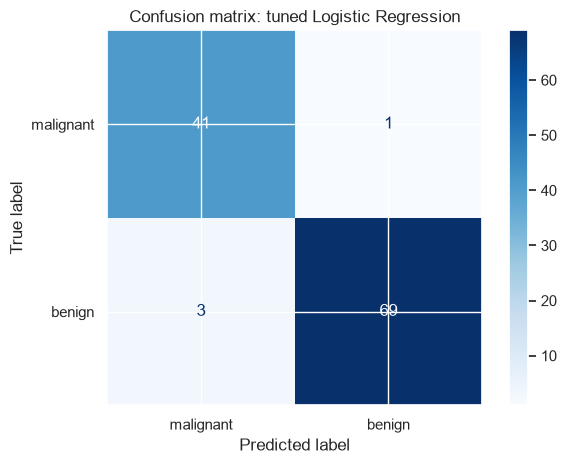

In [7]:
param_grid = {"model__C": [0.01, 0.1, 1, 10, 100]}
grid = GridSearchCV(
    logistic_pipeline,
    param_grid=param_grid,
    scoring="recall",  # default positive label is 1 (benign), so use custom scorer below instead
    cv=5,
    n_jobs=-1
)
# Use a scorer that explicitly treats malignant (label 0) as the positive class.
from sklearn.metrics import make_scorer
grid = GridSearchCV(
    logistic_pipeline,
    param_grid=param_grid,
    scoring=make_scorer(recall_score, pos_label=0),
    cv=5,
    n_jobs=-1
)
grid.fit(X_train, y_train)
improved_model = grid.best_estimator_
print("Best parameters:", grid.best_params_)
print("Best cross-validation malignant recall:", round(grid.best_score_, 3))

improved_pred = improved_model.predict(X_test)
improved_metrics = evaluate_model("Tuned Logistic Regression", improved_model, X_test, y_test)
display(pd.DataFrame([improved_metrics]).round(3))
print(classification_report(y_test, improved_pred,
                            target_names=["malignant", "benign"], zero_division=0))
ConfusionMatrixDisplay.from_predictions(
    y_test, improved_pred, display_labels=["malignant", "benign"], cmap="Blues"
)
plt.title("Confusion matrix: tuned Logistic Regression")
plt.tight_layout()
plt.show()

## 8. Findings, limitations and recommendations
- **Findings:** Use the metric table and confusion matrices above to identify which model has the strongest malignant recall and overall balance on the held-out test set.
- **Limitations:** This is a single, relatively small, pre-packaged dataset. The test results may vary with a different split, and the data may not represent all populations or clinical settings.
- **Recommendations:** Prioritise sensitivity to malignant cases, review false negatives with domain experts, validate on independent data, and assess fairness and generalisability before any real-world use.
- **Ethics:** Patient-related predictions must protect privacy, be checked for bias, and support rather than replace qualified clinical judgement.
- **Important:** This notebook is for educational purposes only and must not be used to diagnose patients.

## References
- Wolberg, W. H., Street, W. N., & Mangasarian, O. L. Wisconsin Diagnostic Breast Cancer dataset, available through scikit-learn's `load_breast_cancer` dataset loader.
- Pedregosa, F. et al. (2011). Scikit-learn: Machine Learning in Python. *Journal of Machine Learning Research*, 12, 2825–2830.
- Scikit-learn documentation: `load_breast_cancer`, `Pipeline`, `LogisticRegression`, `RandomForestClassifier`, and model evaluation metrics.